In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


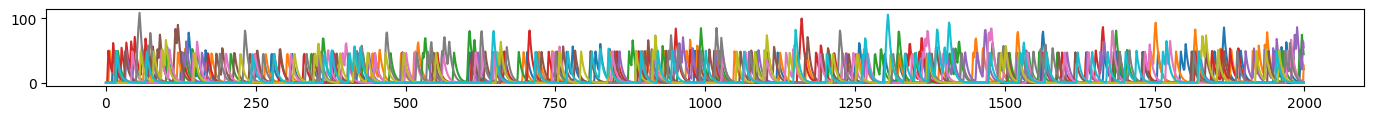

In [311]:
n_timepoints = 1_000
n_components = 10
interp_factor = 2

clean = np.zeros((n_components, n_timepoints * interp_factor))

x = 0
a = 0.7

b = 0

firing_prop = 0.05

spikes = list()

for i in range(n_components):
    spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

for c_ix in range(n_components):
    for i in range(2, n_timepoints):
        clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

    x_ = np.arange(0, n_timepoints * interp_factor)
    xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
    clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

n_timepoints *= 2

fig = plt.figure(figsize=(17, 1))
for i in range(n_components):
    plt.plot(clean[i])

In [335]:
noise = 20

In [336]:
n_pixels = 3

series = list()

for i in range(n_components):
    for j in range(n_pixels):
        noisy = clean[i] + np.random.normal(scale=noise, size=n_timepoints)
        noisy -= noisy.mean()
        series.append(noisy)

series = np.vstack(series)

<Axes: >

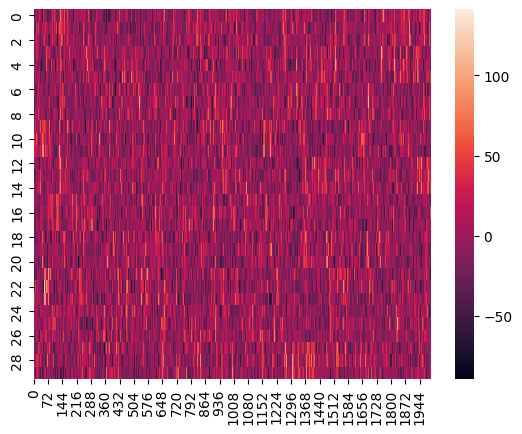

In [337]:
sns.heatmap(series)

In [338]:
series[-1] = np.random.normal(scale=noise, size=n_timepoints)
series[-1] -= series[-1].mean()

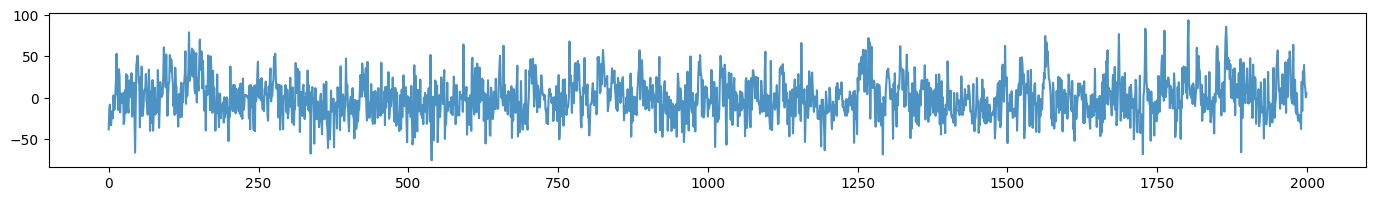

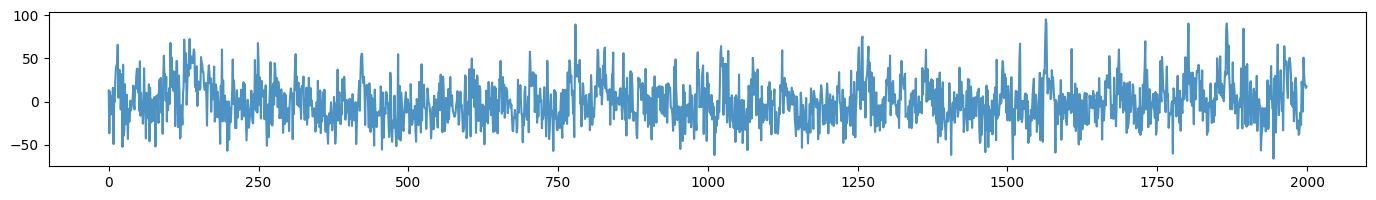

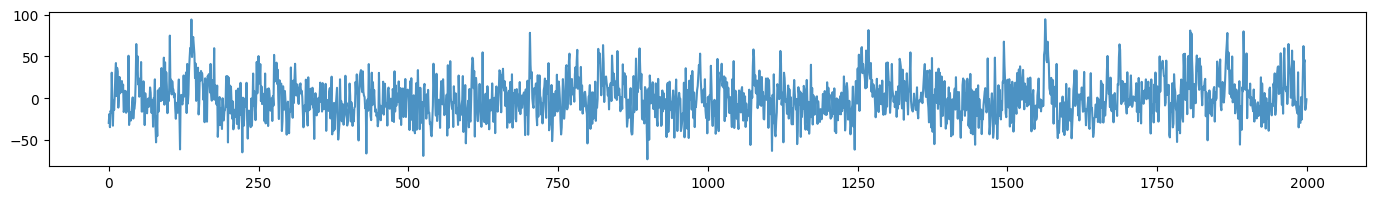

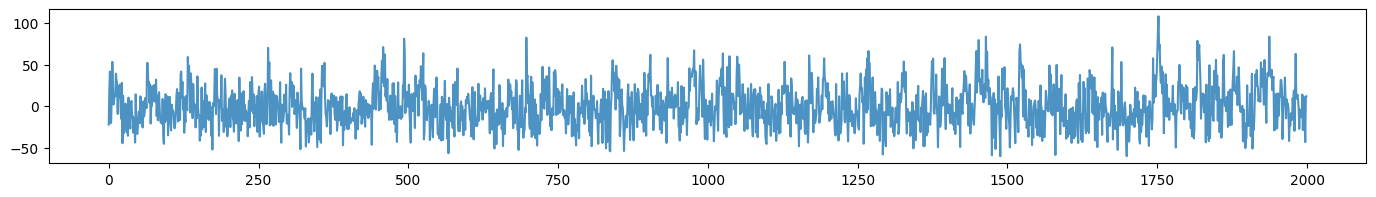

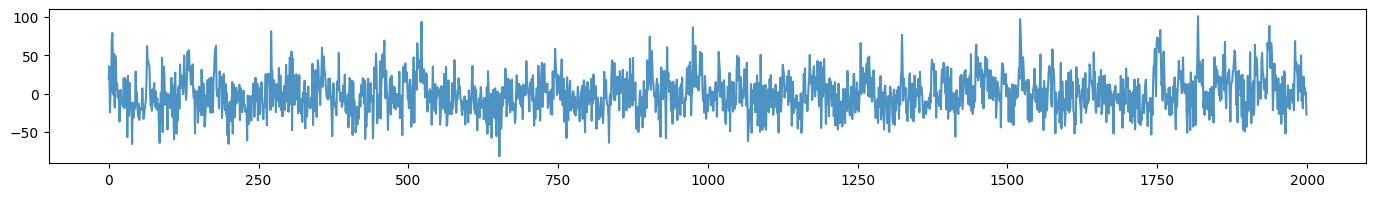

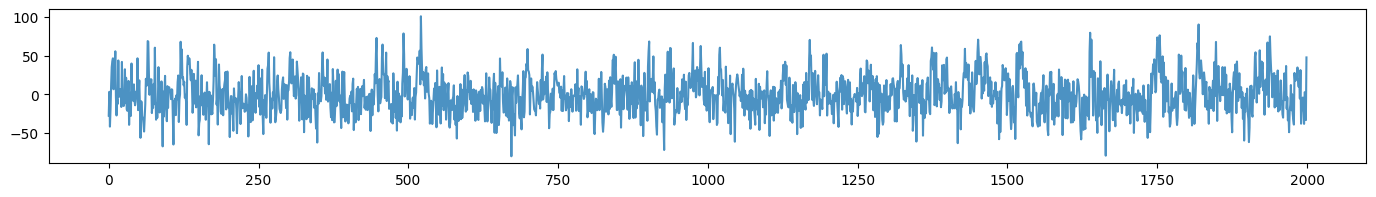

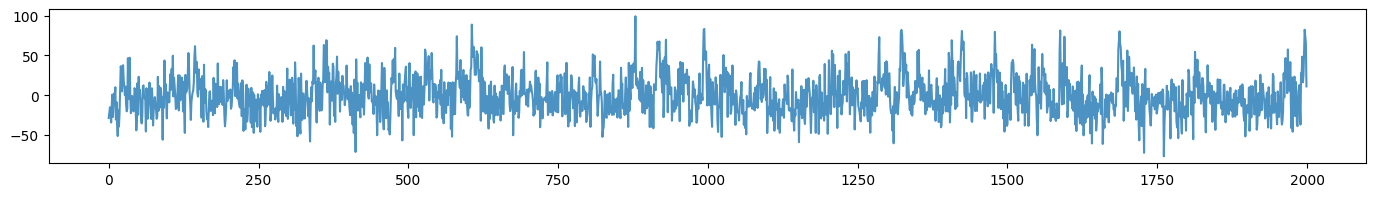

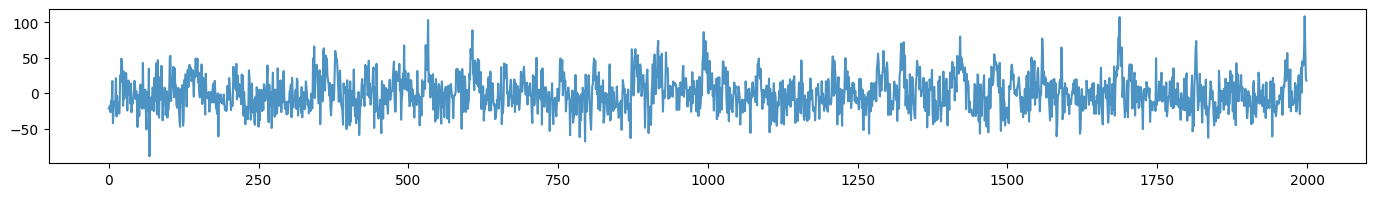

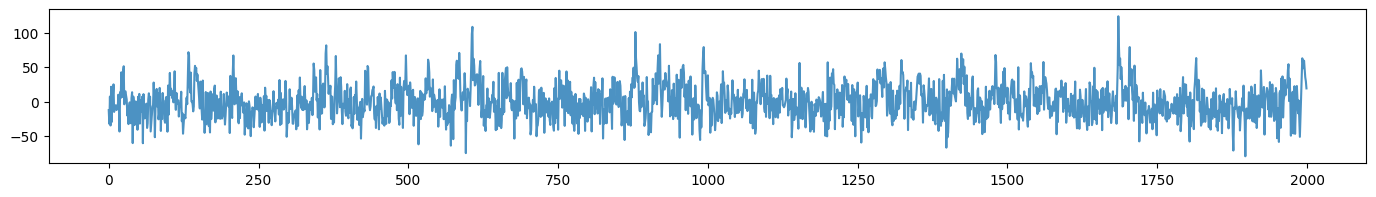

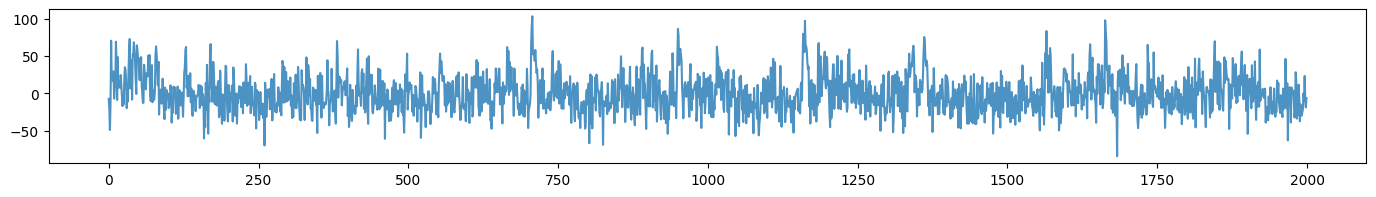

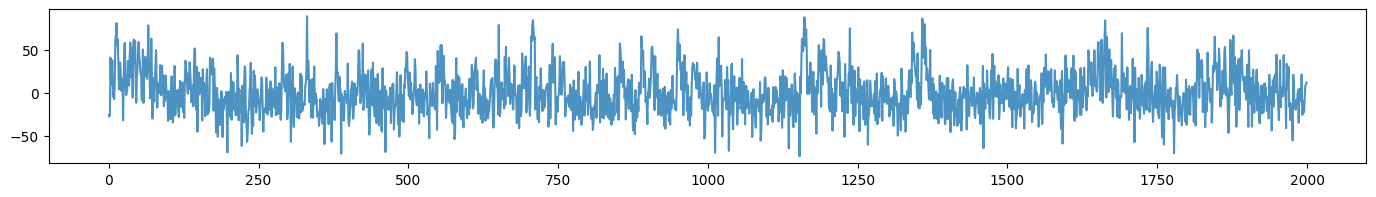

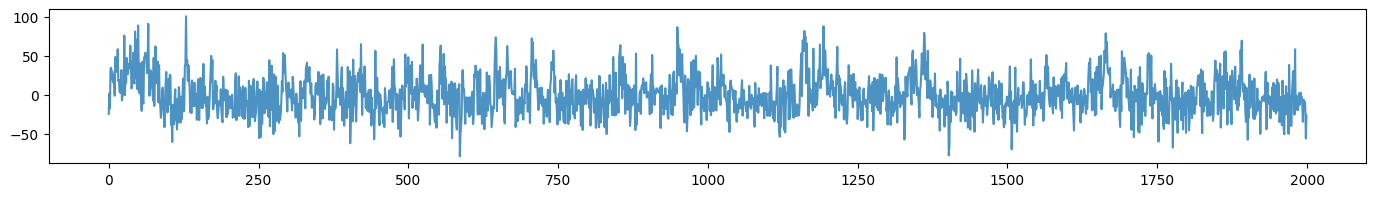

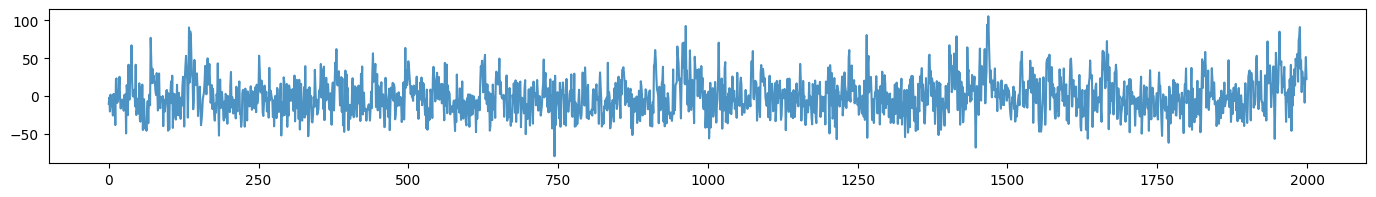

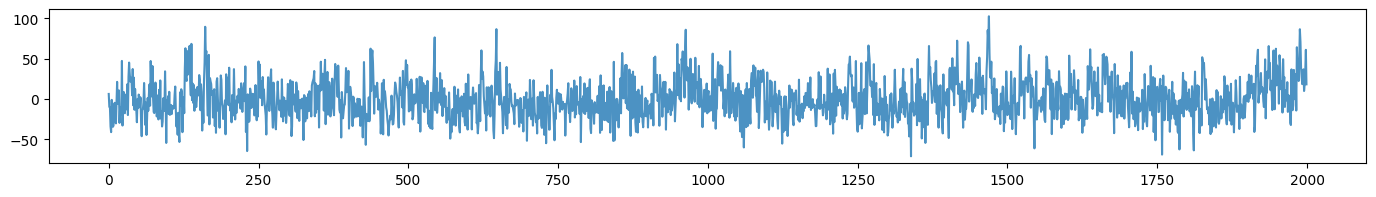

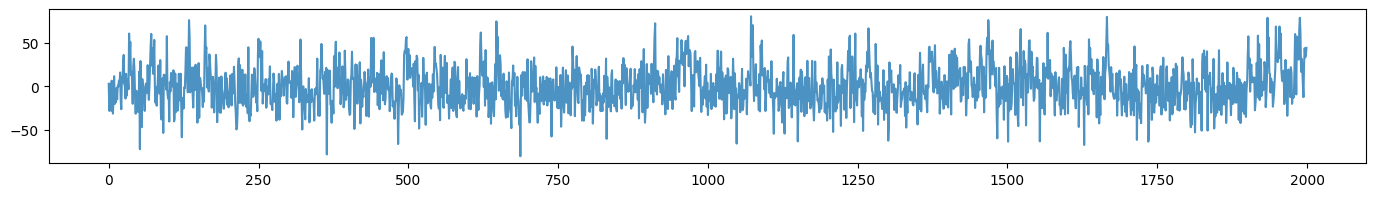

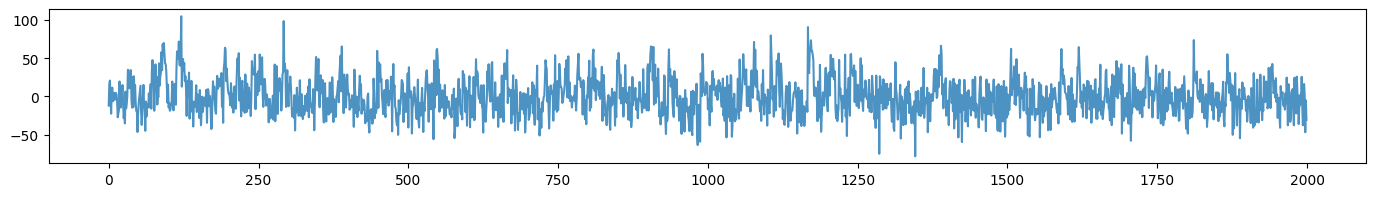

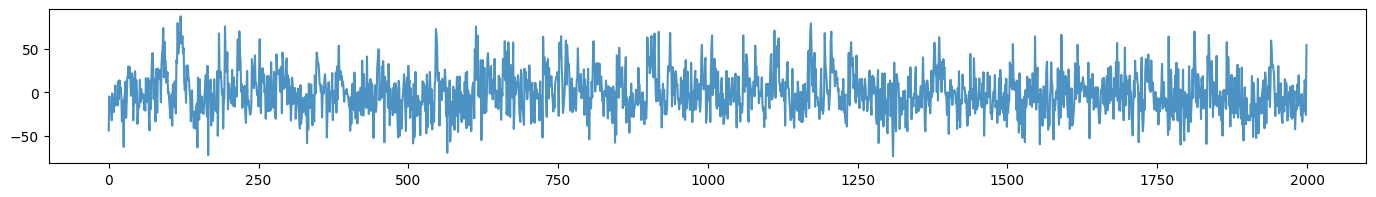

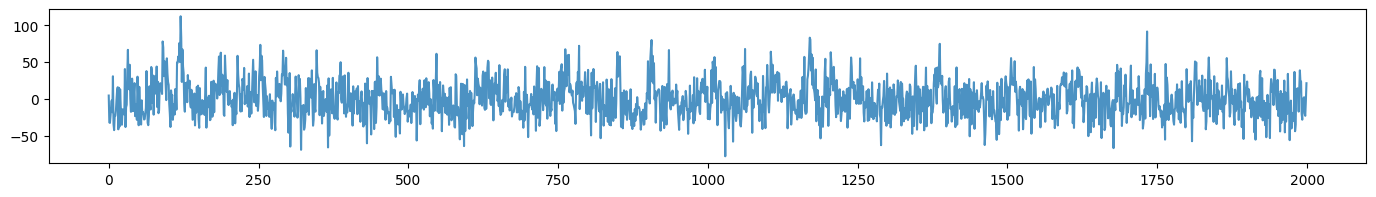

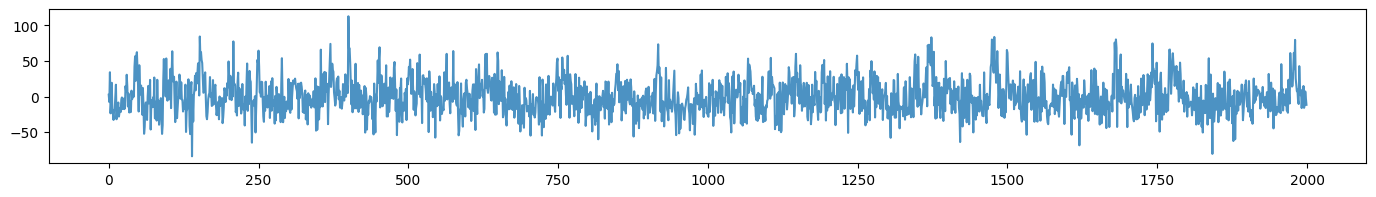

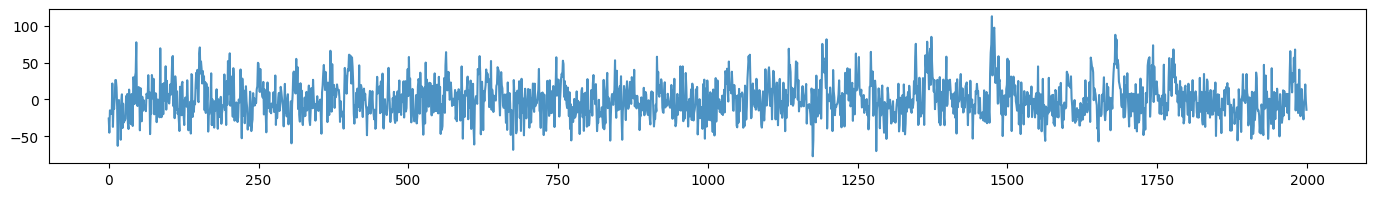

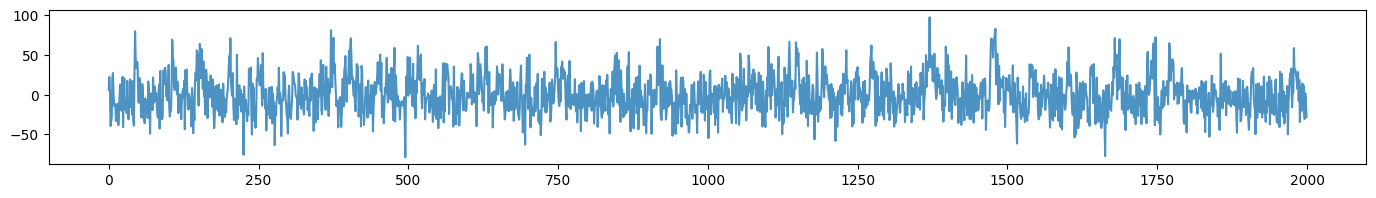

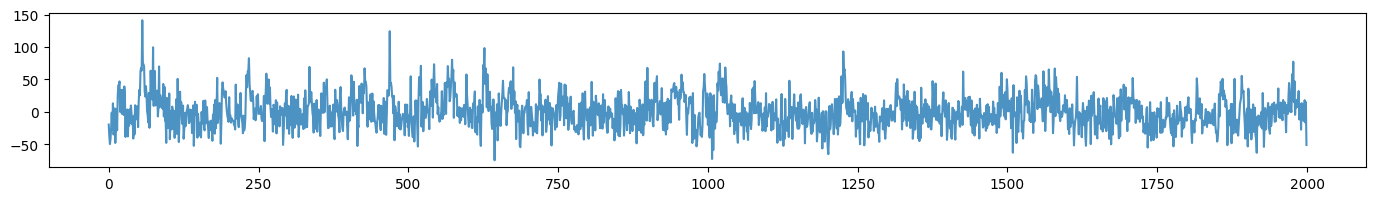

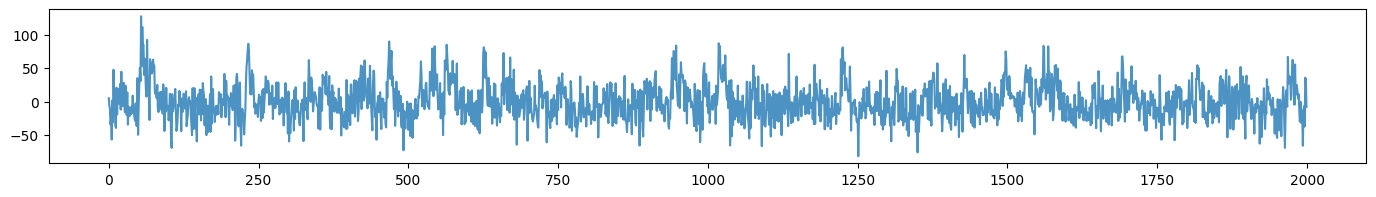

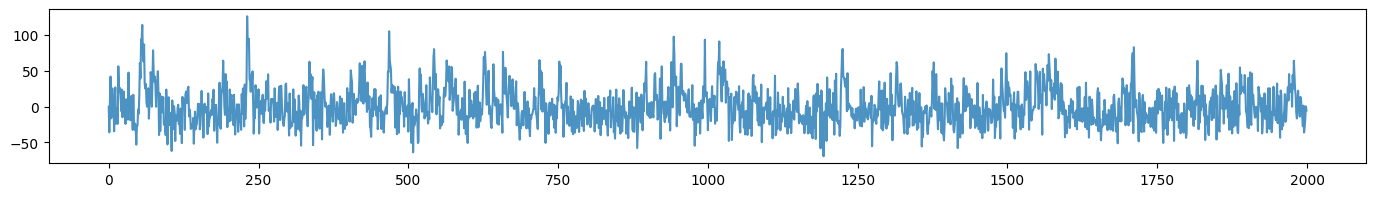

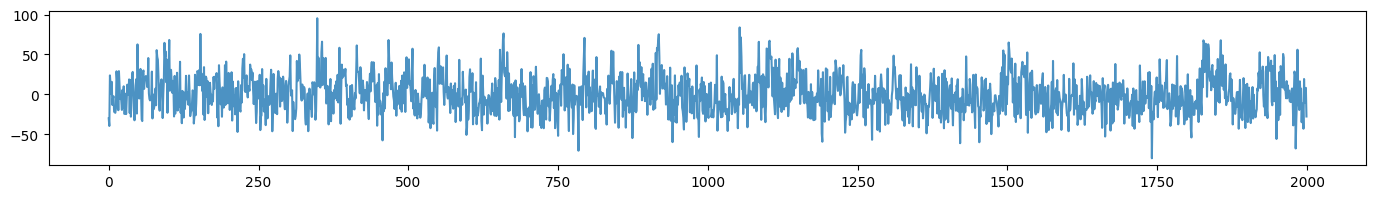

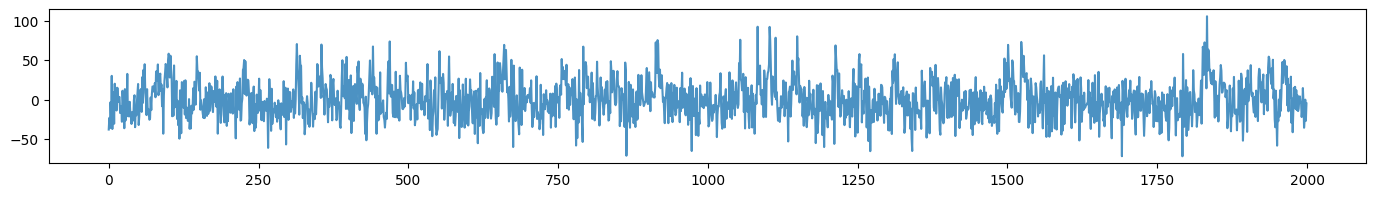

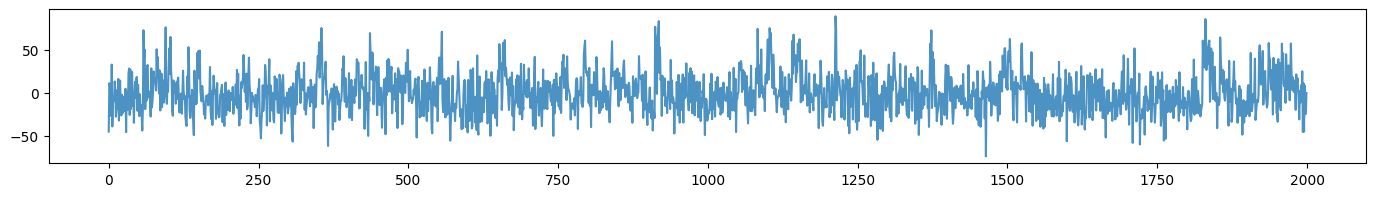

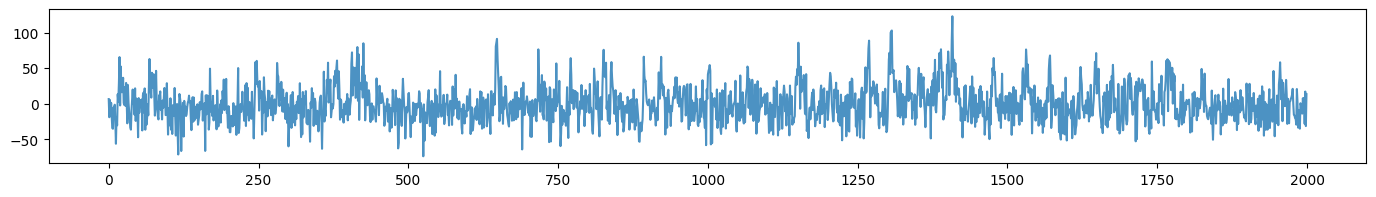

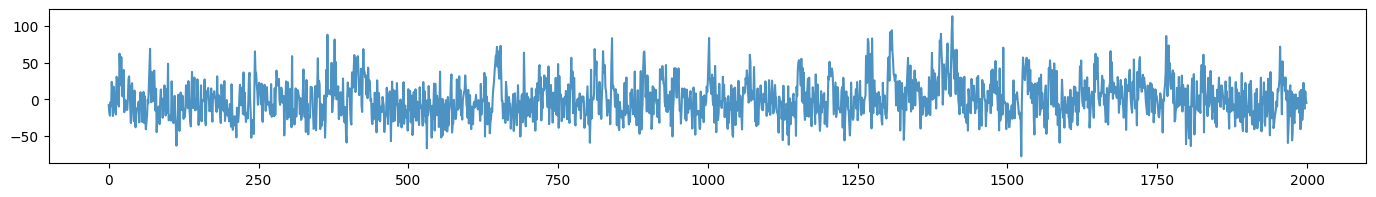

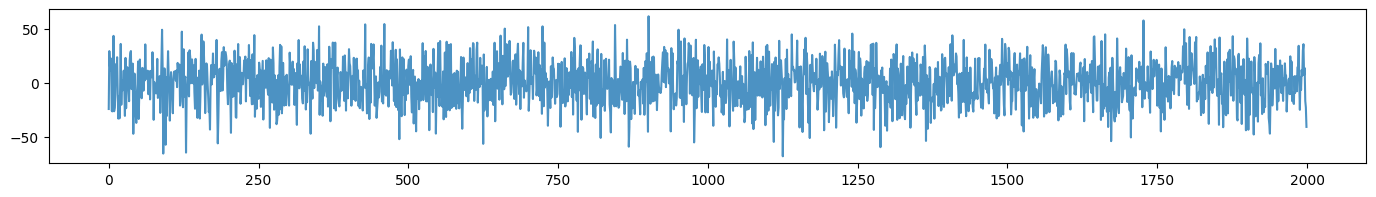

In [339]:
for i in range(n_pixels * n_components):
    fig = plt.figure(figsize=(17, 2))
    plt.plot(series[i], alpha=0.8)
    plt.show()

# plt.plot(clean, c="k", alpha=0.3)

In [340]:
series.mean(axis=1)

array([-5.11590770e-16,  6.82121026e-16, -1.70530257e-16,  0.00000000e+00,
       -2.27373675e-16, -1.59161573e-15, -9.09494702e-16, -5.68434189e-16,
       -1.93267624e-15,  5.40012479e-16, -1.19371180e-15, -2.04636308e-15,
       -6.82121026e-16, -6.82121026e-16,  3.97903932e-16,  2.27373675e-16,
       -2.27373675e-16, -1.64845915e-15, -1.02318154e-15, -4.54747351e-16,
       -7.38964445e-16, -2.04636308e-15, -1.02318154e-15, -9.09494702e-16,
       -9.09494702e-16, -5.11590770e-16,  3.69482223e-16, -4.54747351e-16,
        2.27373675e-16, -1.70530257e-16])

In [341]:
series.std(axis=1)

array([24.44057736, 24.71093174, 24.10079375, 24.79056051, 25.21008613,
       25.07106558, 24.78660484, 24.92826045, 24.98124793, 24.97051877,
       25.1685184 , 24.83067726, 24.2656638 , 24.25958318, 23.82088335,
       24.27144968, 24.45064905, 24.50874272, 24.6858949 , 24.90019511,
       24.17836503, 25.5858833 , 26.93992122, 25.76850519, 23.8259793 ,
       24.24260372, 23.29197257, 25.37663942, 25.86364958, 20.0995177 ])

In [342]:
series.ptp(axis=1)

array([169.68208849, 162.74022206, 167.470739  , 168.63331493,
       183.36851853, 180.9748805 , 175.47876755, 197.78379497,
       202.88604387, 187.88580886, 162.65719108, 178.96268845,
       184.41386555, 173.57414329, 161.29327732, 183.77004565,
       160.29803191, 190.12547388, 196.58172288, 189.62290366,
       175.90695592, 215.98022136, 209.28350171, 195.24797853,
       175.61975967, 177.88103559, 163.61573483, 196.59879315,
       190.13369389, 129.6049231 ])

In [343]:
from scipy import linalg

In [344]:
import seaborn as sns

/tmp/ipykernel_627775/1268377926.py:28: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


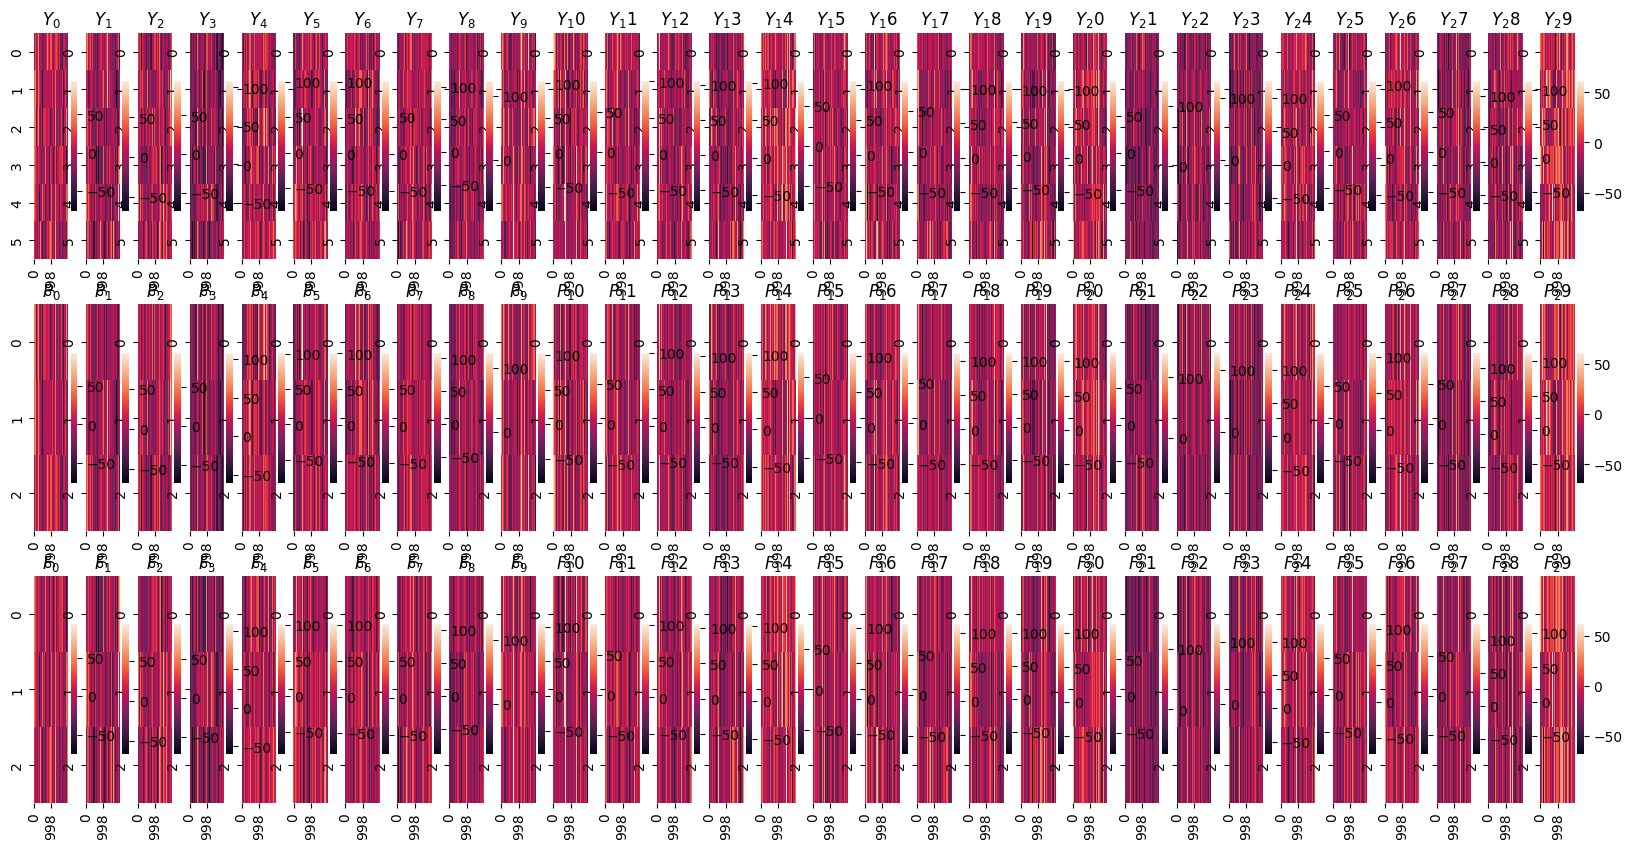

In [345]:
center = 100
w = 6

Ys = list()
Ps = list()
Fs = list()

fig, axs = plt.subplots(3, series.shape[0], figsize=(20, 10))

for i in range(series.shape[0]):
    y = linalg.hankel(series[i, :w], series[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)
        
    sns.heatmap(y, ax=axs[0, i])
    axs[0, i].set_title(f"$Y_{i}$")

    sns.heatmap(p, ax=axs[1, i])
    axs[1, i].set_title(f"$P_{i}$")

    sns.heatmap(f, ax=axs[2, i])
    axs[2, i].set_title(f"$F_{i}$")

plt.tight_layout()

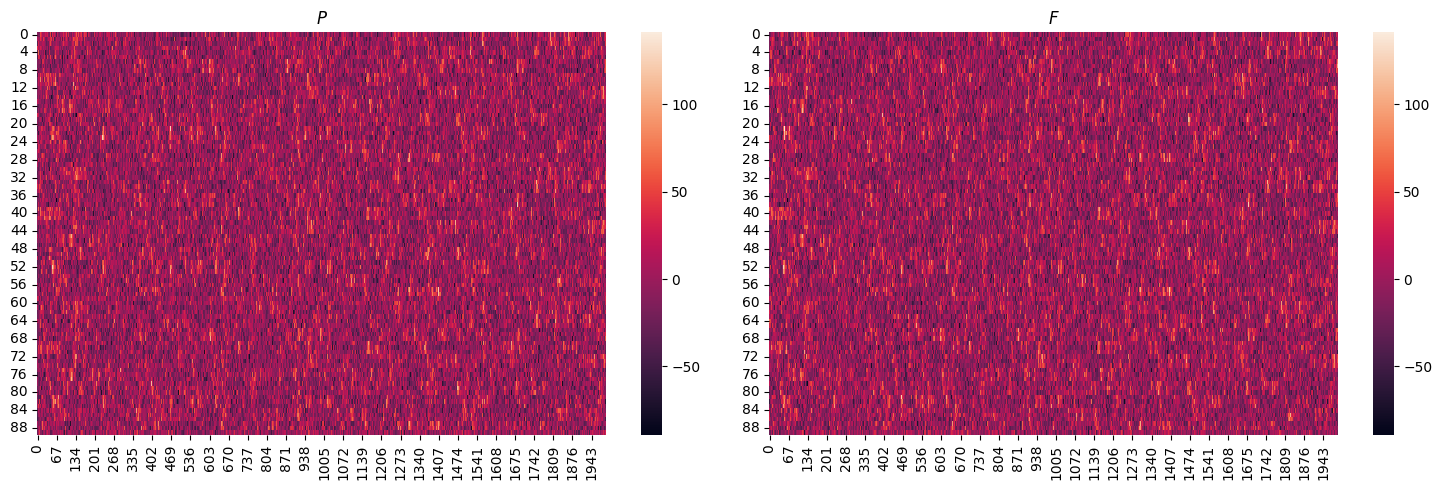

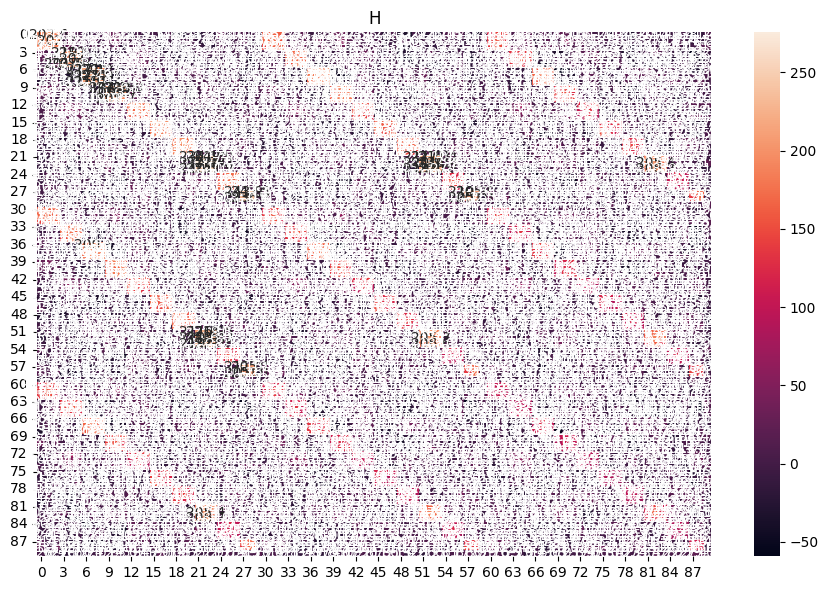

In [346]:
P_F_shape = (int(w / 2) * series.shape[0], n_timepoints - w)

P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(series.shape[0]):
    P[i::series.shape[0]] = Ps[i]
    F[i::series.shape[0]] = Fs[i]

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(P, ax=axs[0])
axs[0].set_title(f"$P$")

sns.heatmap(F, ax=axs[1])
axs[1].set_title(f"$F$")
fig.tight_layout()
plt.show()

H = (F @ P.T) / P.shape[1]

fig = plt.figure(figsize=(9, 6))
sns.heatmap(H, annot=True, fmt="0.1f")
plt.title("H")
fig.tight_layout()
plt.show()

In [347]:
from itertools import product

In [348]:
iterator = [tuple(reversed(ixs)) for ixs in product(*[range(0, int(w / 2) * series.shape[0], series.shape[0])]*2)]
iterator

[(0, 0),
 (30, 0),
 (60, 0),
 (0, 30),
 (30, 30),
 (60, 30),
 (0, 60),
 (30, 60),
 (60, 60)]

In [349]:
Hp = np.zeros((int(w / 2)**2, series.shape[0]**2))

for row_ix, (block_row_ix, block_col_ix) in enumerate(iterator):
    Hp[row_ix] = H[block_row_ix:block_row_ix + series.shape[0], block_col_ix:block_col_ix + series.shape[0]].ravel()

<Axes: >

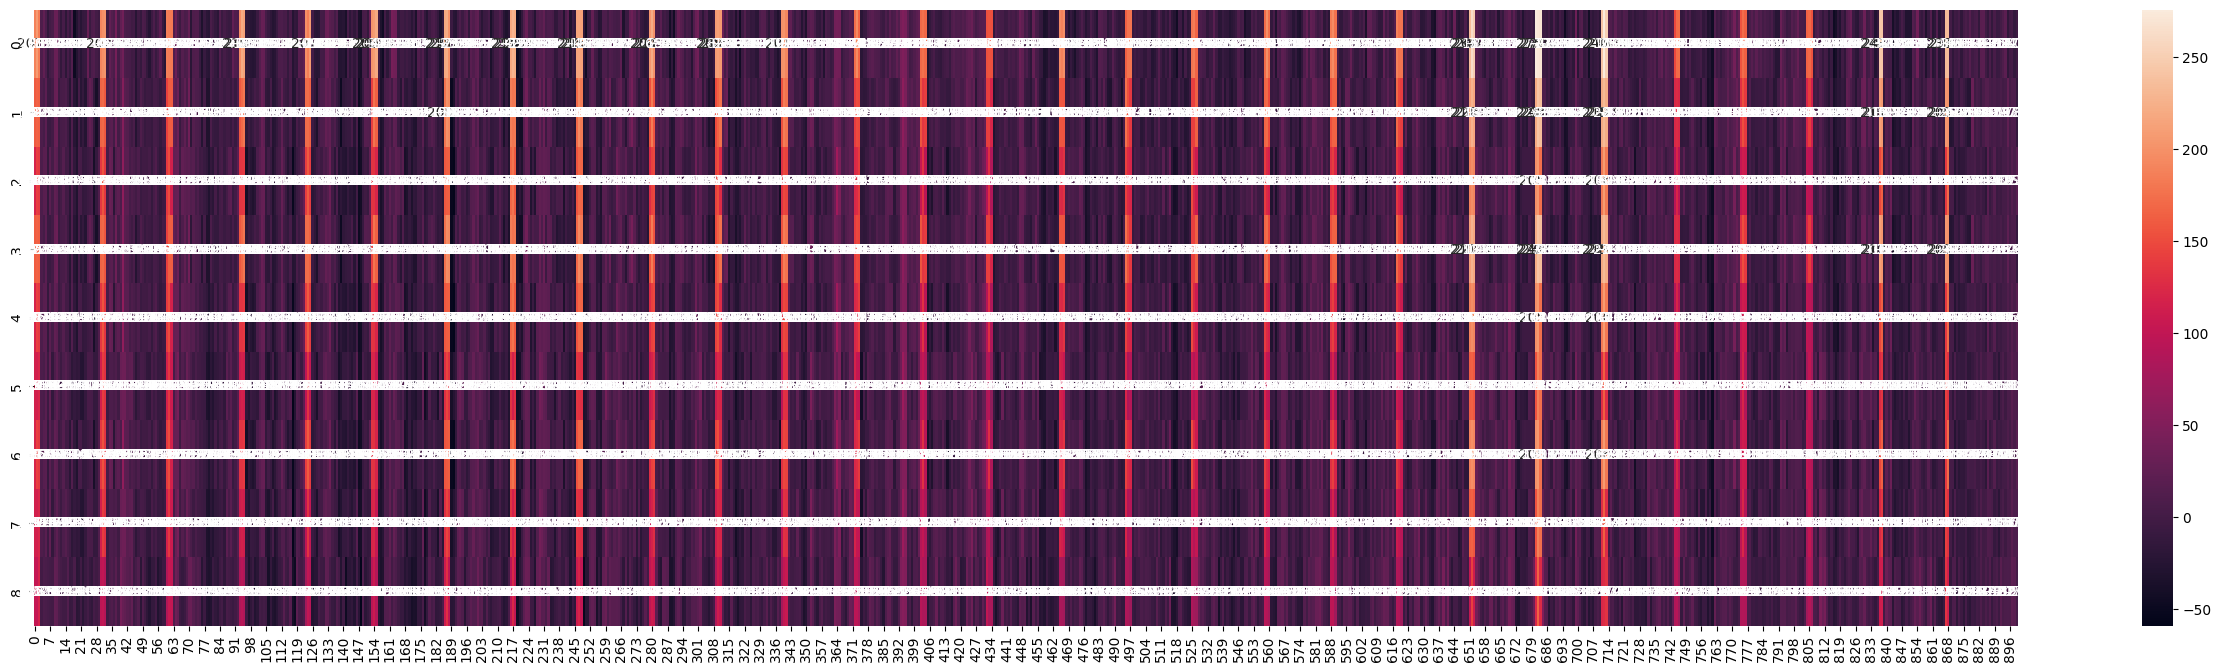

In [350]:
fig = plt.figure(figsize=(32, 8))

sns.heatmap(Hp, annot=True, fmt="0.1f")

In [351]:
u, s, v = linalg.svd(Hp)

Text(0.5, 1.0, 'V')

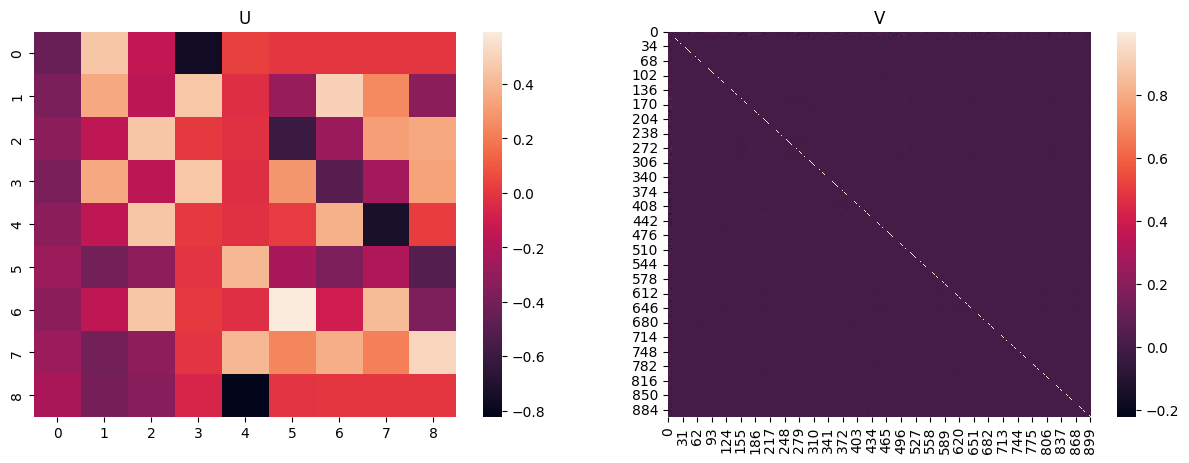

In [352]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(u, ax=axs[0])
axs[0].set_title("U")
sns.heatmap(v, ax=axs[1])
axs[1].set_title("V")

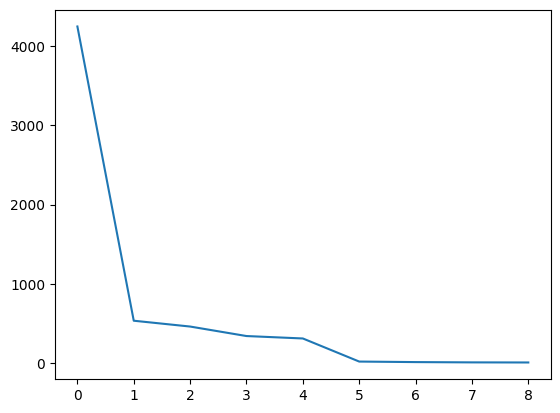

In [353]:
plt.plot(s)

Text(0.5, 1.0, '$V^r$')

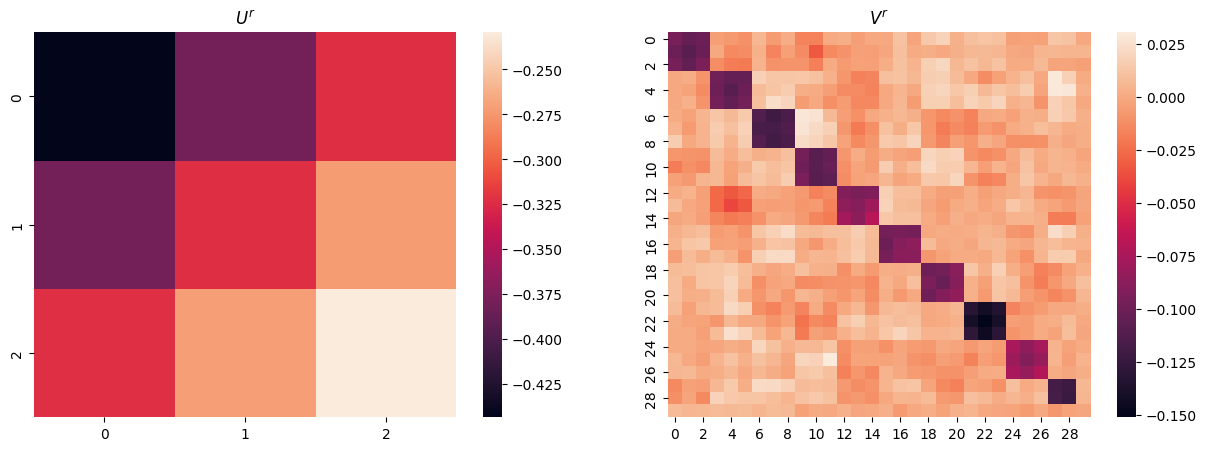

In [354]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
sns.heatmap(u_r, ax=axs[0])
axs[0].set_title("$U^r$")

v_r = v[0].reshape(series.shape[0], series.shape[0])
sns.heatmap(v_r, ax=axs[1])
axs[1].set_title("$V^r$")

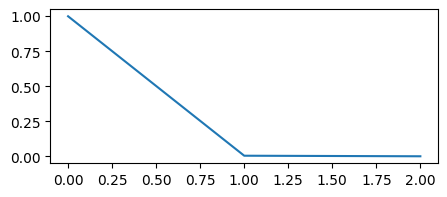

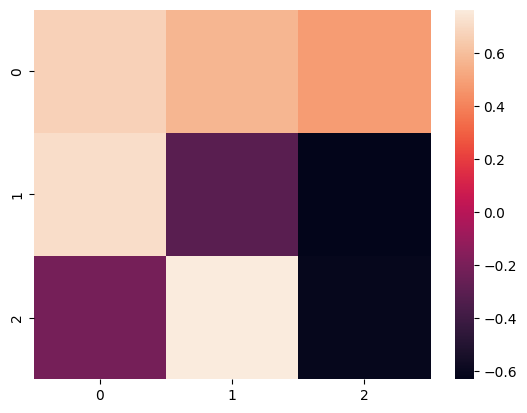

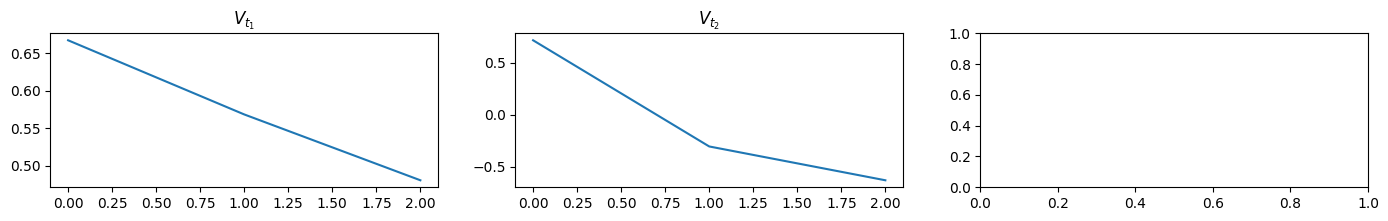

In [355]:
u_t, s_t, v_t = linalg.svd(u_r)

fig = plt.figure(figsize=(5, 2))
plt.plot(s_t)
plt.show()

sns.heatmap(v_t)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 2))

for i in range(2):
    axs[i].plot(v_t[i])
    axs[i].set_title(f"$V_{{t_{i + 1}}}$")
    
plt.show()

In [356]:
u_s, s_s, v_s = linalg.svd(v_r)

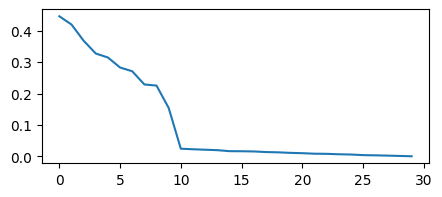

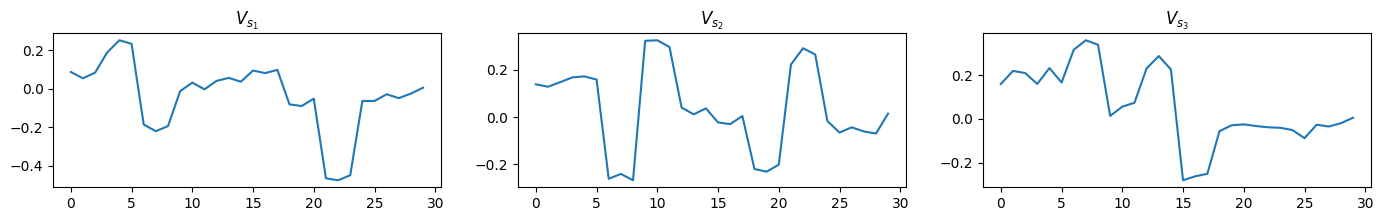

In [357]:
fig = plt.figure(figsize=(5, 2))
plt.plot(s_s)

fig, axs = plt.subplots(1, 3, figsize=(17, 2))

for i in range(3):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [358]:
v_s[0]

array([ 0.0860198 ,  0.05317743,  0.08280713,  0.1881992 ,  0.25067091,
        0.23226356, -0.18684291, -0.22163729, -0.19474585, -0.01364926,
        0.03077868, -0.0040336 ,  0.0399086 ,  0.0552231 ,  0.03566552,
        0.09344648,  0.08026796,  0.0969959 , -0.08218477, -0.09087447,
       -0.05249817, -0.46610467, -0.47637289, -0.45031348, -0.06451056,
       -0.06451567, -0.02956586, -0.04984482, -0.02587377,  0.00448779])

In [359]:
filts = list()

for i in range(n_components):
    filts.append(np.kron(v_t[0], v_s[i]))

<Axes: >

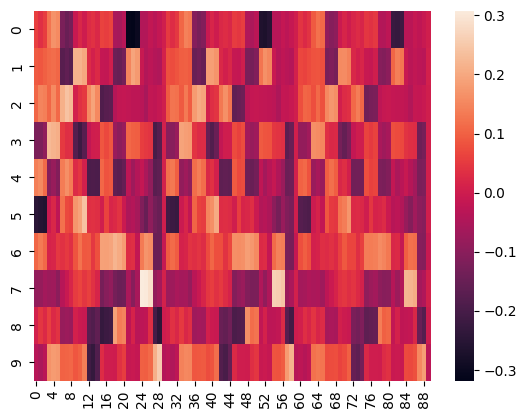

In [362]:
sns.heatmap(np.vstack(filts))

In [363]:
P.shape

(90, 1994)

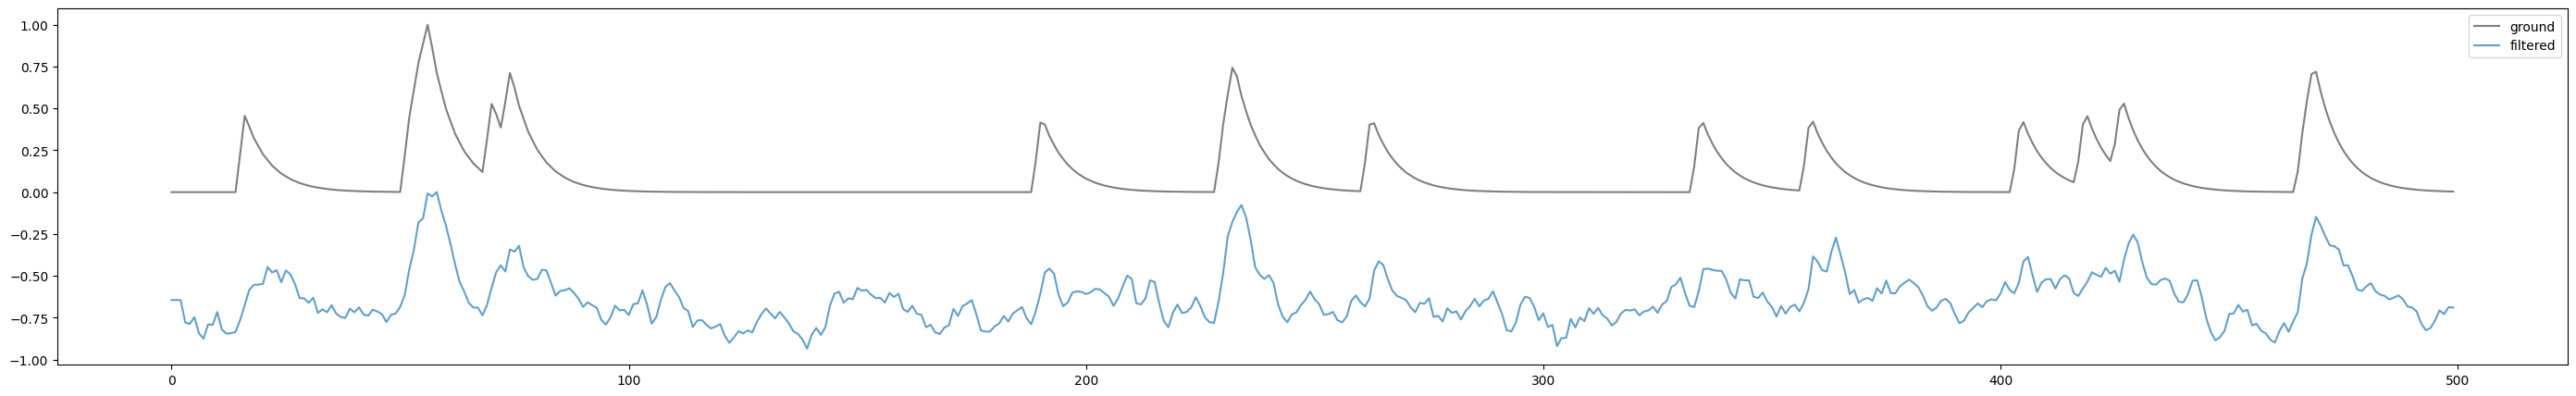

In [374]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filts[0] @ P


filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[7, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(-filtered[indices], label="filtered", alpha=0.7)
# plt.plot(series[:3].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()

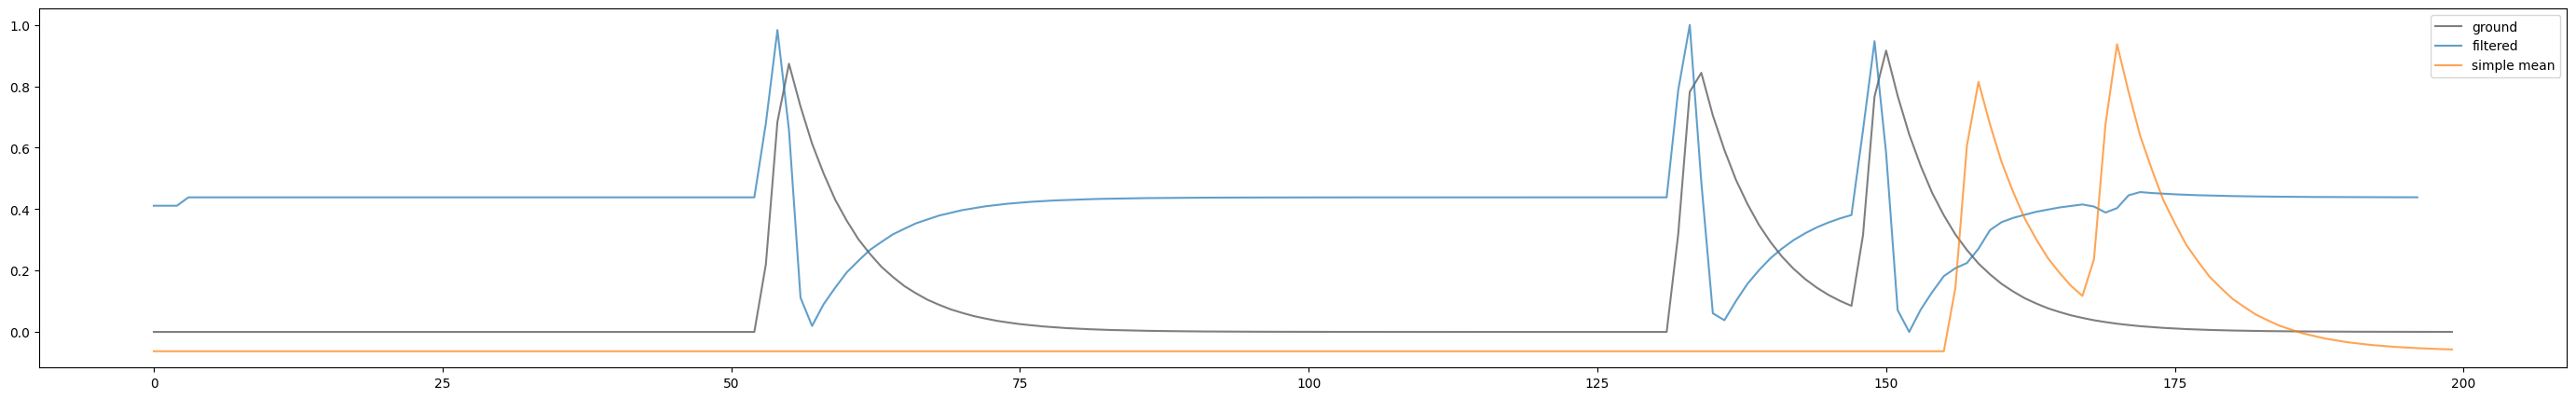

In [211]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filt2 @ P


filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
plt.plot(series[4:-1].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()